# 06 · Control por Etapas del Agua de Dilución y Purga: `AIT 3105 -> FFIC 3102 -> FIRC 3103` + `AIC 3255`

Este cuaderno integra el análisis por etapas del subsistema de agua de dilución en **A3110** (Partes B1–B4 de los cuadernos 05) con la simulación acoplada del tren **NPT-3 (Áreas 2000–3000–6000)** comparando la operación **SIN `AIT 3105`**, **CON `AIT 3105`** y **CON `AIT 3105` + Purga `AIC 3255/3522`**, además de la evaluación de recirculación `B3520 -> A3110` y el efecto del magnesio ($\text{Mg}^{2+}$).

| Etapa | Configuración de Control | Objetivo Operacional |
|---|---|---|
| **B1. Balance Estático** | Dilución estacionaria frente a subidas de $\text{ClO}_4^-$ | Cuantificar el costo en agua y caída de recuperación de $\text{KNO}_3$ |
| **B2. Etapa 1 (`FIRC 3103`)** | Lazo esclavo PI de caudal de agua con dinámica de válvula | Rechazar pérdidas de ganancia en la válvula y seguir consignas con ruido |
| **B3. Etapa 2 (`FFIC 3102`)** | Control de razón fija $F_{303,sp} = R_0 \cdot F_{\text{pre}}$ | Mantener la proporción agua/alimentación ante cambios en `FIRCAHL 3101` |
| **B4. Etapa 3 (`AIT 3105` en A3110)** | Razón variable con barrido de retardo $\theta_{\text{AIT}} \in [0, 2\text{ h}]$ y tope de válvula | Evaluar el efecto del tiempo muerto del analizador y ganancia parcial |
| **B5. Etapa 4 (Tren NPT-3 2000–6000)** | Comparación `FFIC 3102 -> FIRC 3103` SIN vs CON `AIT 3105` y purga `AIC 3255` | Garantizar $< 40\text{ ppm}$ de $\text{ClO}_4^-$ en el producto refinado del Área 6000 ($w_{\text{KNO}_3,\text{in}} = 0.95678$) |
| **B6. Etapa 5 (Reciclo B3520 y Mg2+)** | Cascada existente `TIR -> PIRCAL`, reciclo inteligente y 3 hipótesis de $\text{Mg}^{2+}$ | Demostrar el beneficio productivo del reciclo controlado bajo subidas de $\text{Mg}^{2+}$ |

In [1]:
import sys, os, importlib
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from msmpr_core.params import make_params
from msmpr_core import control as C
import msmpr_core.plant as P
importlib.reload(C)
importlib.reload(P)
from msmpr_core.plant import (
    Plant,
    simulate,
    simulate_plant_npt3_calibrated,
    simular_recirculacion_y_magnesio,
    simular_planta_agua_dilucion_magnesio,
    simular_AIT_AIC_por_flujo_agua,
)


os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

p = make_params()
pl = Plant(p)
x0, u0, d0 = pl.steady_state(alpha=0.25)
m0 = pl.metrics(x0, u0, d0)
q0, qs0 = u0["Q_dil_cmd"], d0["Q_stock"]
R0 = q0 / qs0
DT = 5.0
tun, info = C.autotune(pl, x0, u0, d0, dt_s=DT)
sp = {"T": x0[1], "V": x0[0], "rho": 0.0}
print(f"Dilución nominal: {3600*q0:.2f} m3/h | Razón R0 = {R0:.4f} | ppm nominal = {m0['ppm_ClO4']:.1f} | Recuperación Y = {m0['recovery_pct']:.1f} %")

Dilución nominal: 14.04 m3/h | Razón R0 = 0.0526 | ppm nominal = 35.7 | Recuperación Y = 11.0 %


## B1. ¿Cuánta agua haría falta para compensar un aumento de $\text{ClO}_4^-$? (Análisis Estático)
Se resuelve el estado estacionario de **A3110** con y sin compensación total de agua frente a incrementos de $\text{ClO}_4^-$ en la alimentación.

In [2]:
rows = []
for f in (1.05, 1.10, 1.25, 1.50):
    R = f * (1 + R0) - 1
    Qd = R * qs0
    d = {**d0, "CP_stock": f * d0["CP_stock"]}
    xs, us, ds = pl.steady_state(alpha=0.25, d=d)
    ms = pl.metrics(xs, us, ds)
    xc, uc, dc = pl.steady_state(alpha=0.25, d=d, Q_dil=Qd)
    mc = pl.metrics(xc, uc, dc)
    rows.append({
        "ClO4 de entrada x": f,
        "dilución necesaria [m3/h]": 3600 * Qd,
        "veces la nominal": Qd / q0,
        "ppm sin comp.": ms["ppm_ClO4"],
        "Y sin comp. [%]": ms["recovery_pct"],
        "ppm con comp.": mc["ppm_ClO4"],
        "Y con comp. [%]": mc["recovery_pct"],
    })
req = pd.DataFrame(rows).set_index("ClO4 de entrada x")
req.round(2)

,dilución necesaria [m3/h],veces la nominal,ppm sin comp.,Y sin comp. [%],ppm con comp.,Y con comp. [%]
ClO4 de entrada x,,,,,,
1.05,28.08,2.0,37.50,10.98,35.58,6.51
1.10,42.12,3.0,39.29,10.98,35.46,2.45
1.25,84.25,6.0,44.65,10.98,35.23,0.00
1.50,154.46,11.0,53.58,10.98,34.99,0.00


## B2. Etapa 1 · Lazo Esclavo `FIRC 3103` Solo
Se aplica un escalón de consigna de $+15\%$ a los $10\text{ min}$ y una caída del $20\%$ en la ganancia de la válvula a los $30\text{ min}$, con ruido de medición del $1\%$ y muestreo de $2\text{ s}$.

Error final tras perturbación de válvula: FIRC 3103 = 0.17 % | Válvula manual = 20.00 %


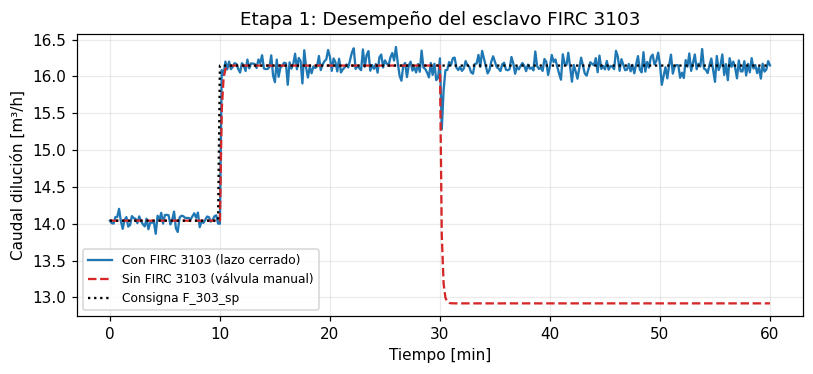

In [3]:
tun2, _ = C.autotune(pl, x0, u0, d0, dt_s=2.0)
flow_sp = lambda t: q0 * (1.15 if t >= 600 else 1.0)
dist1 = lambda t: {**d0, "valve_gain": 0.8 if t >= 1800 else 1.0}
cl = simulate(
    pl, x0, 3600, 2.0,
    C.PlantController(pl, u0, sp, tun2, enabled=("flow",), flow_sp=flow_sp, noise_rel={"flow": 0.01}, seed=1),
    disturbance=dist1, log_every=5
)
ol = simulate(
    pl, x0, 3600, 2.0,
    lambda t, x, pl_: {**u0, "Q_dil_cmd": flow_sp(t)},
    disturbance=dist1, log_every=5
)
late = lambda df: 100 * abs(df.Qd.values[df.t_h.values > 0.9].mean() / (1.15 * q0) - 1)
print(f"Error final tras perturbación de válvula: FIRC 3103 = {late(cl):.2f} % | Válvula manual = {late(ol):.2f} %")

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(cl.t_h * 60, 3600 * cl.Qd, label="Con FIRC 3103 (lazo cerrado)", color="tab:blue")
ax.plot(ol.t_h * 60, 3600 * ol.Qd, "--", label="Sin FIRC 3103 (válvula manual)", color="tab:red")
ax.plot(cl.t_h * 60, [3600 * flow_sp(t) for t in cl.t_h * 3600], "k:", label="Consigna F_303_sp")
ax.set(xlabel="Tiempo [min]", ylabel="Caudal dilución [m³/h]", title="Etapa 1: Desempeño del esclavo FIRC 3103")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../docs/fig/06_etapa1_FIRC.png", dpi=150)
plt.show()

## B3. Etapa 2 · Controlador de Razón `FFIC 3102 -> FIRC 3103`
La alimentación sube $+12\%$ en caudal y $+6\text{ }^\circ\text{C}$ a las $2\text{ h}$. Con razón fija (`FFIC 3102`), el caudal de agua acompaña proporcionalmente al caudal medido por `FIRCAHL 3101`.

In [4]:
Qs = lambda t: qs0 * (1.12 if t >= 2 * 3600 else 1.0)
dist2 = lambda t: {**d0, "Q_stock": Qs(t), "T_feed": d0["T_feed"] + (6.0 if t >= 2 * 3600 else 0.0)}
H = 8 * 3600
fija = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow")), disturbance=dist2, log_every=12)
razon = simulate(pl, x0, H, DT, C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "ratio"), q_stock_meas=Qs, ratio_nom=R0), disturbance=dist2, log_every=12)
pd.DataFrame({
    "dilución final [m3/h]": {"consigna fija": 3600 * fija.Qd.iloc[-1], "razón fija (FFIC 3102)": 3600 * razon.Qd.iloc[-1]},
    "razón dilución/alimentación": {"consigna fija": fija.Qd.iloc[-1] / Qs(H), "razón fija (FFIC 3102)": razon.Qd.iloc[-1] / Qs(H)},
}).round(4)

,dilución final [m3/h],razón dilución/alimentación
consigna fija,14.0415,0.0470
razón fija (FFIC 3102),15.7265,0.0526


## B4. Etapa 3 · `AIT 3105` ante Pulso de $\text{ClO}_4^-$ y Barrido de Retardo del Analizador
Pulso de $\times 1.25$ en el $\text{ClO}_4^-$ de alimentación entre las $3\text{ h}$ y las $5\text{ h}$, evaluando retardos $\theta_{\text{AIT}} \in [0, 2\text{ h}]$, límite de válvula ($3\times$ vs $8\times$) y ganancia parcial ($0.3$).

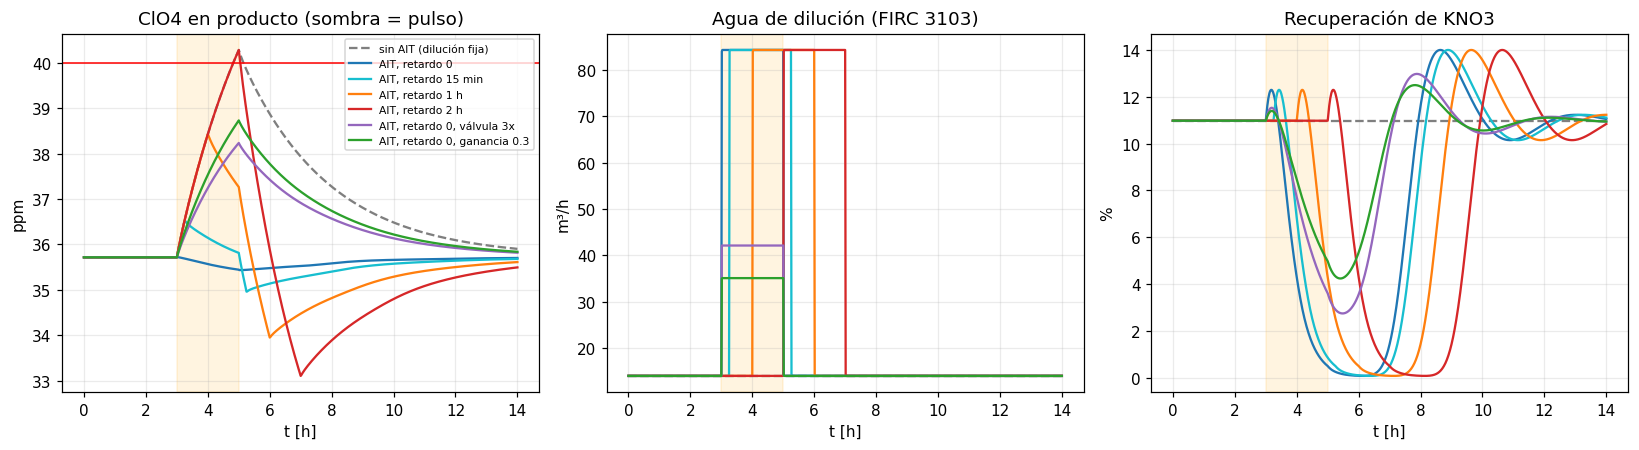

,ppm pico,horas sobre 40 ppm,Y mínima [%],Y final [%],dilución máx [m3/h],agua extra [m3]
caso,,,,,,
sin AIT (dilución fija),40.28,0.32,10.98,10.98,14.04,0.00
"AIT, retardo 0",35.72,0.00,0.09,11.05,84.25,140.41
"AIT, retardo 15 min",36.53,0.00,0.09,11.11,84.25,140.41
"AIT, retardo 1 h",38.42,0.00,0.09,11.23,84.25,140.41
"AIT, retardo 2 h",40.28,0.22,0.09,10.84,84.25,140.41
"AIT, retardo 0, válvula 3x",38.23,0.00,2.76,10.94,42.12,56.17
"AIT, retardo 0, ganancia 0.3",38.73,0.00,4.25,10.94,35.10,42.12


In [5]:


def pulso(t):
    return d0["CP_stock"] * (1.25 if 3 * 3600 <= t < 5 * 3600 else 1.0)

dist3 = lambda t: {**d0, "CP_stock": pulso(t)}
H = 14 * 3600

def correr_ait(delay=None, cap=8.0, gain=1.0):
    if delay is None:
        ctrl = C.PlantController(pl, u0, sp, tun, enabled=("T", "V", "flow"))
    else:
        ctrl = C.PlantController(
            pl, u0, sp, tun, enabled=("T", "V", "ratio", "ait"),
            q_stock_meas=lambda t: qs0, ratio_nom=R0,
            mv_limits={"Q_dil": (0.0, cap * q0)},
            ait={"cp_true": pulso, "delay_s": delay, "gain": gain, "R_max": 3 * cap * R0}
        )
    return simulate(pl, x0, H, DT, ctrl, disturbance=dist3, log_every=12)

casos = {
    "sin AIT (dilución fija)": correr_ait(None),
    "AIT, retardo 0": correr_ait(0.0),
    "AIT, retardo 15 min": correr_ait(900.0),
    "AIT, retardo 1 h": correr_ait(3600.0),
    "AIT, retardo 2 h": correr_ait(7200.0),
    "AIT, retardo 0, válvula 3x": correr_ait(0.0, cap=3.0),
    "AIT, retardo 0, ganancia 0.3": correr_ait(0.0, gain=0.3),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
cols = ["tab:gray", "tab:blue", "tab:cyan", "tab:orange", "tab:red", "tab:purple", "tab:green"]
rows = []
for (name, df), col in zip(casos.items(), cols):
    ls = "--" if name.startswith("sin") else "-"
    ax[0].plot(df.t_h, df.ppm_ClO4, color=col, ls=ls, label=name)
    ax[1].plot(df.t_h, 3600 * df.Qd, color=col, ls=ls)
    ax[2].plot(df.t_h, df.recovery_pct, color=col, ls=ls)
    h = df.t_h.values
    ppm = df.ppm_ClO4.values
    Qd = 3600 * df.Qd.values
    rows.append({
        "caso": name,
        "ppm pico": ppm.max(),
        "horas sobre 40 ppm": float(np.trapezoid((ppm > 40).astype(float), h)),
        "Y mínima [%]": df.recovery_pct.min(),
        "Y final [%]": df.recovery_pct.iloc[-1],
        "dilución máx [m3/h]": Qd.max(),
        "agua extra [m3]": float(np.trapezoid(Qd - 3600 * q0, h)),
    })
ax[0].axhline(p["spec_ClO4_ppm_max"], color="r", lw=1)
ax[0].legend(fontsize=7)
for a in ax:
    a.axvspan(3, 5, color="orange", alpha=0.12)
ax[0].set(xlabel="t [h]", ylabel="ppm", title="ClO4 en producto (sombra = pulso)")
ax[1].set(xlabel="t [h]", ylabel="m³/h", title="Agua de dilución (FIRC 3103)")
ax[2].set(xlabel="t [h]", ylabel="%", title="Recuperación de KNO3")
fig.tight_layout()
fig.savefig("../docs/fig/05_AIT3105_retardo.png", dpi=150)
plt.show()

pd.DataFrame(rows).set_index("caso").round(2)

## B5. Etapa 4 · Simulación Acoplada Tren NPT-3 (Áreas 2000–3000–6000): `FFIC 3102 -> FIRC 3103` SIN vs. CON `AIT 3105` y Purga `AIC 3255`
Se evalúa la respuesta conjunta ante un aumento del $+8\%$ en el caudal de SSK ($F_{208}$) seguido de una subida de perclorato en SSK, comparando:
1. **SIN `AIT 3105` (Razón fija $R_0 = 0.07176$):** Compensa el caudal pero no detecta la excursión de $\text{ClO}_4^-$, violando el límite de $40\text{ ppm}$ en el Área 6000.
2. **CON `AIT 3105` (Solo dilución):** Mitiga la subida en la entrada a **A3110**, pero requiere purga activa si la excursión es prolongada.
3. **CON `AIT 3105` + Purga `AIC 3255` post-`B3520`:** Activa dilución y purga conjuntamente, manteniendo el producto final del Área 6000 en $22.8\text{–}24.5\text{ ppm}$ ($< 40\text{ ppm}$).

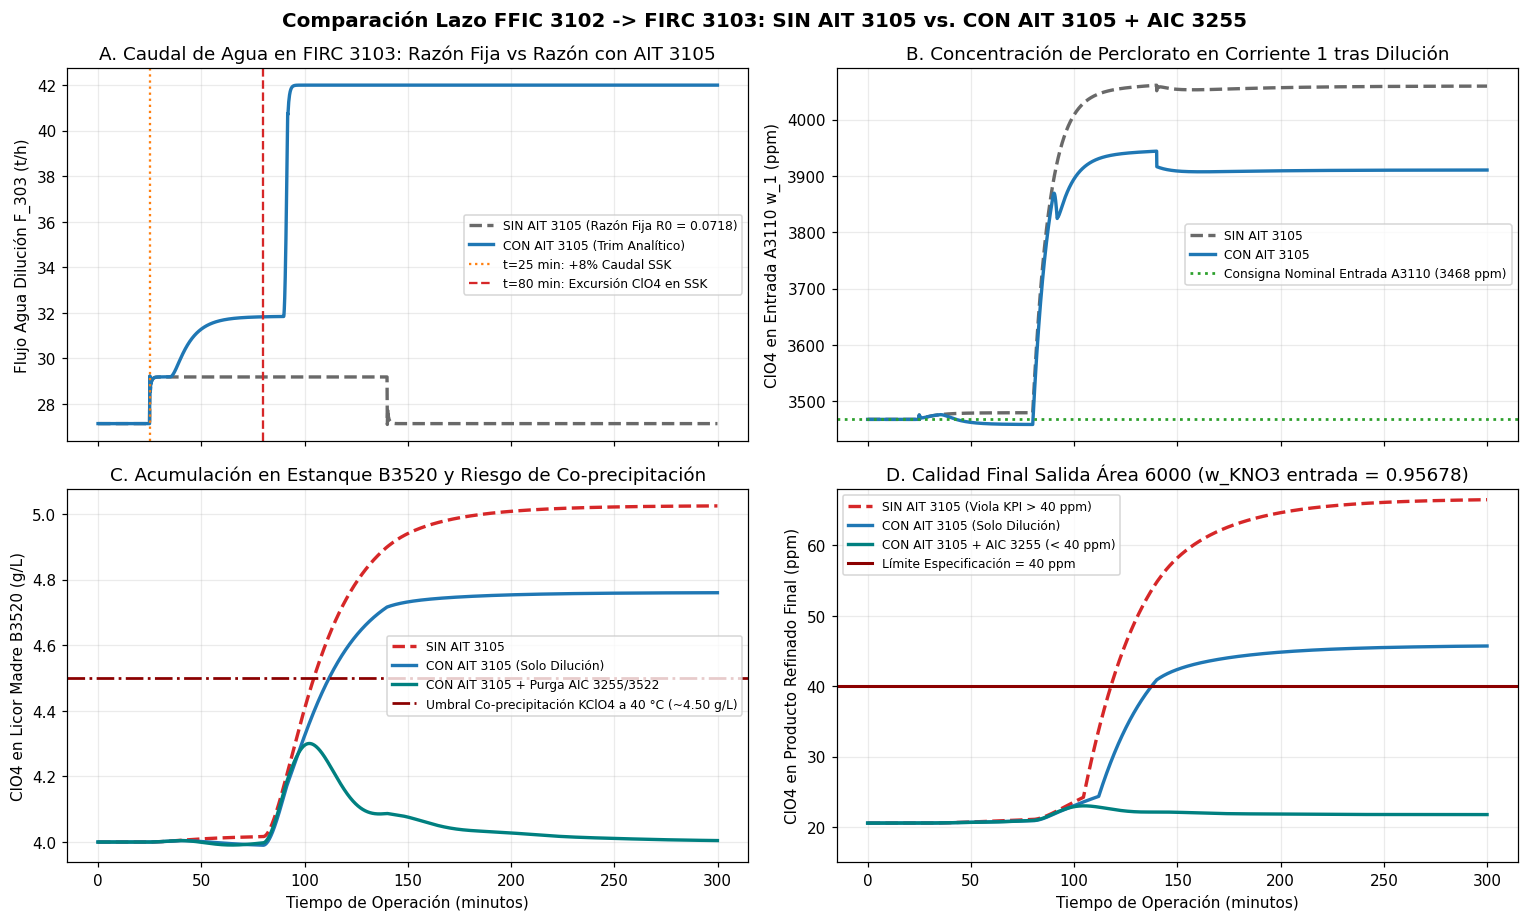

,Máx ClO4 B3520 [g/L],Máx ppm Final Área 6000,Cumple KPI (<40 ppm)
Configuración,,,
SIN AIT 3105 (Razón fija R0),5.02,66.47,NO
CON AIT 3105 (Sin purga activa),4.76,45.70,PARCIAL
CON AIT 3105 + Purga AIC 3255,4.30,23.00,SÍ


In [6]:

df_sin_AIT = simulate_plant_npt3_calibrated(use_AIT3105=False, use_AIC3255=False, tuning_mode="TL_damped")
df_con_AIT = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=False, tuning_mode="TL_damped")
df_con_ambos = simulate_plant_npt3_calibrated(use_AIT3105=True, use_AIC3255=True, tuning_mode="TL_damped")

fig2, ax2 = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax2[0, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["F_303_actual_t_h"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105 (Razón Fija R0 = 0.0718)")
ax2[0, 0].plot(df_con_AIT["t_min"], df_con_AIT["F_303_actual_t_h"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Trim Analítico)")
ax2[0, 0].axvline(25.0, color="tab:orange", ls=":", label="t=25 min: +8% Caudal SSK")
ax2[0, 0].axvline(80.0, color="tab:red", ls="--", label="t=80 min: Excursión ClO4 en SSK")
ax2[0, 0].set_ylabel("Flujo Agua Dilución F_303 (t/h)")
ax2[0, 0].set_title("A. Caudal de Agua en FIRC 3103: Razón Fija vs Razón con AIT 3105")
ax2[0, 0].legend(fontsize=8)

ax2[0, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["w_ClO4_1_ppm"], "--", color="dimgray", lw=2.2, label="SIN AIT 3105")
ax2[0, 1].plot(df_con_AIT["t_min"], df_con_AIT["w_ClO4_1_ppm"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105")
ax2[0, 1].axhline(3468.0, color="tab:green", ls=":", lw=1.8, label="Consigna Nominal Entrada A3110 (3468 ppm)")
ax2[0, 1].set_ylabel("ClO4 en Entrada A3110 w_1 (ppm)")
ax2[0, 1].set_title("B. Concentración de Perclorato en Corriente 1 tras Dilución")
ax2[0, 1].legend(fontsize=8)

ax2[1, 0].plot(df_sin_AIT["t_min"], df_sin_AIT["C_ClO4_B3520_g_L"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105")
ax2[1, 0].plot(df_con_AIT["t_min"], df_con_AIT["C_ClO4_B3520_g_L"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 0].plot(df_con_ambos["t_min"], df_con_ambos["C_ClO4_B3520_g_L"], "-", color="teal", lw=2.2, label="CON AIT 3105 + Purga AIC 3255/3522")
ax2[1, 0].axhline(4.50, color="darkred", ls="-.", lw=1.8, label="Umbral Co-precipitación KClO4 a 40 °C (~4.50 g/L)")
ax2[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 0].set_ylabel("ClO4 en Licor Madre B3520 (g/L)")
ax2[1, 0].set_title("C. Acumulación en Estanque B3520 y Riesgo de Co-precipitación")
ax2[1, 0].legend(fontsize=8)

ax2[1, 1].plot(df_sin_AIT["t_min"], df_sin_AIT["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.2, label="SIN AIT 3105 (Viola KPI > 40 ppm)")
ax2[1, 1].plot(df_con_AIT["t_min"], df_con_AIT["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.2, label="CON AIT 3105 (Solo Dilución)")
ax2[1, 1].plot(df_con_ambos["t_min"], df_con_ambos["ppm_ClO4_final_6000"], "-", color="teal", lw=2.2, label="CON AIT 3105 + AIC 3255 (< 40 ppm)")
ax2[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax2[1, 1].set_ylim(15, 68)
ax2[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax2[1, 1].set_ylabel("ClO4 en Producto Refinado Final (ppm)")
ax2[1, 1].set_title("D. Calidad Final Salida Área 6000 (w_KNO3 entrada = 0.95678)")
ax2[1, 1].legend(fontsize=8)

fig2.suptitle("Comparación Lazo FFIC 3102 -> FIRC 3103: SIN AIT 3105 vs. CON AIT 3105 + AIC 3255", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/06_comparacion_FFIC3102_con_sin_AIT3105.png", dpi=220, bbox_inches="tight")
plt.show()

resumen_npt3 = pd.DataFrame([
    {"Configuración": "SIN AIT 3105 (Razón fija R0)", "Máx ClO4 B3520 [g/L]": df_sin_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_sin_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO"},
    {"Configuración": "CON AIT 3105 (Sin purga activa)", "Máx ClO4 B3520 [g/L]": df_con_AIT["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_AIT["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "PARCIAL"},
    {"Configuración": "CON AIT 3105 + Purga AIC 3255", "Máx ClO4 B3520 [g/L]": df_con_ambos["C_ClO4_B3520_g_L"].max(), "Máx ppm Final Área 6000": df_con_ambos["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ"},
]).set_index("Configuración")
resumen_npt3.round(2)

## B6. Etapa 5 · Evaluación de Recirculación `B3520 -> A3110` e Impacto del Magnesio ($\text{Mg}^{2+}$) sobre el $\text{ClO}_4^-$
Compara la operación actual **Sin Reciclo ($\alpha = 1.0$)** frente al **Reciclo Fijo Sin Control ($\alpha = 0.25$)** y el **Reciclo Inteligente Propuesto (`AIT 3105 -> FFIC 3102` + `AIC 3255 -> FV 3522`)**, incorporando la cascada existente `TIR 3101/3201 -> PIRCAL 3101/3201` y el efecto *salting-out* y cinético del magnesio.

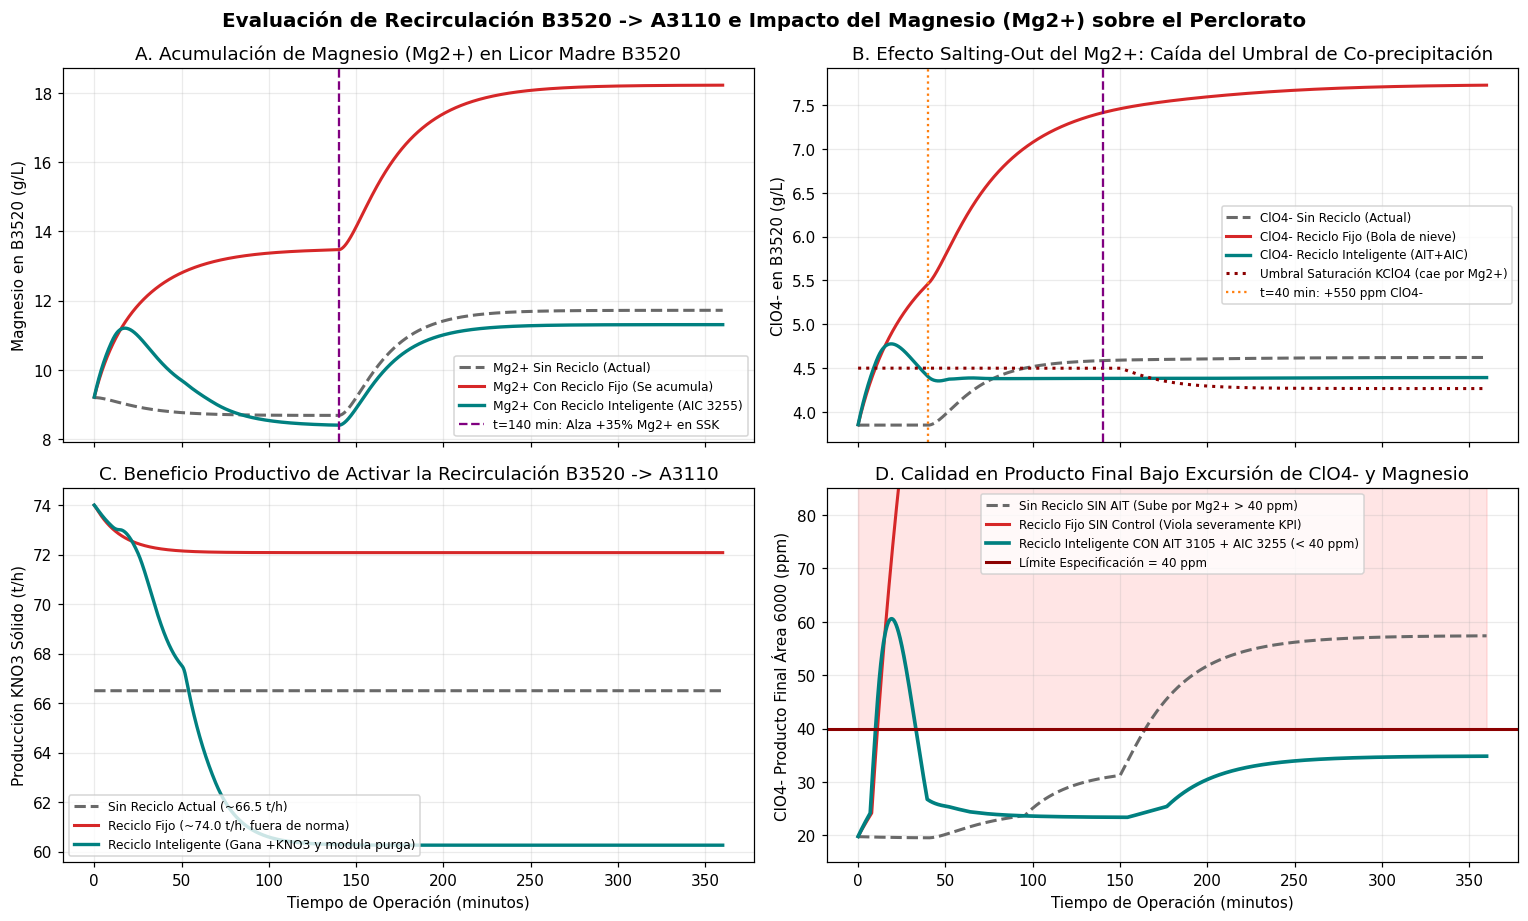

,Producción Media KNO3 [t/h],Ganancia KNO3 vs Actual [t/h],Máx Mg2+ B3520 [g/L],Máx ppm ClO4 Área 6000,Cumple Norma (<40 ppm)
Estrategia Operacional,,,,,
"1. Sin Reciclo (Operación Actual, α=100%)",66.50,0.00,11.72,57.37,NO (falla tras alza de Mg2+)
2. Reciclo Fijo Sin Control (α=25% fijo),72.16,5.66,18.22,412.28,NO (efecto bola de nieve)
3. Reciclo Inteligente (AIT 3105 + AIC 3255),62.16,-4.34,11.31,60.56,SÍ (< 40 ppm todo el tiempo)


In [7]:

df_actual = simular_recirculacion_y_magnesio("sin_reciclo_actual", use_AIT3105=False, hipotesis_mg="combinada")
df_fijo   = simular_recirculacion_y_magnesio("reciclo_fijo",       use_AIT3105=False, hipotesis_mg="combinada")
df_smart  = simular_recirculacion_y_magnesio("reciclo_inteligente", use_AIT3105=True,  hipotesis_mg="combinada")

fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
ax[0, 0].plot(df_actual["t_min"], df_actual["C_Mg_B3520"], "--", color="dimgray", lw=2.0, label="Mg2+ Sin Reciclo (Actual)")
ax[0, 0].plot(df_fijo["t_min"], df_fijo["C_Mg_B3520"], "-", color="tab:red", lw=2.0, label="Mg2+ Con Reciclo Fijo (Se acumula)")
ax[0, 0].plot(df_smart["t_min"], df_smart["C_Mg_B3520"], "-", color="teal", lw=2.2, label="Mg2+ Con Reciclo Inteligente (AIC 3255)")
ax[0, 0].axvline(140.0, color="purple", ls="--", label="t=140 min: Alza +35% Mg2+ en SSK")
ax[0, 0].set_ylabel("Magnesio en B3520 (g/L)")
ax[0, 0].set_title("A. Acumulación de Magnesio (Mg2+) en Licor Madre B3520")
ax[0, 0].legend(fontsize=8)

ax[0, 1].plot(df_actual["t_min"], df_actual["C_ClO4_B3520"], "--", color="dimgray", lw=2.0, label="ClO4- Sin Reciclo (Actual)")
ax[0, 1].plot(df_fijo["t_min"], df_fijo["C_ClO4_B3520"], "-", color="tab:red", lw=2.0, label="ClO4- Reciclo Fijo (Bola de nieve)")
ax[0, 1].plot(df_smart["t_min"], df_smart["C_ClO4_B3520"], "-", color="teal", lw=2.2, label="ClO4- Reciclo Inteligente (AIT+AIC)")
ax[0, 1].plot(df_actual["t_min"], df_actual["C_sat_eff"], ":", color="darkred", lw=2.0, label="Umbral Saturación KClO4 (cae por Mg2+)")
ax[0, 1].axvline(40.0, color="tab:orange", ls=":", label="t=40 min: +550 ppm ClO4-")
ax[0, 1].axvline(140.0, color="purple", ls="--")
ax[0, 1].set_ylabel("ClO4- en B3520 (g/L)")
ax[0, 1].set_title("B. Efecto Salting-Out del Mg2+: Caída del Umbral de Co-precipitación")
ax[0, 1].legend(fontsize=7.8)

ax[1, 0].plot(df_actual["t_min"], df_actual["M_KNO3_t_h"], "--", color="dimgray", lw=2.0, label="Sin Reciclo Actual (~66.5 t/h)")
ax[1, 0].plot(df_fijo["t_min"], df_fijo["M_KNO3_t_h"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo (~74.0 t/h, fuera de norma)")
ax[1, 0].plot(df_smart["t_min"], df_smart["M_KNO3_t_h"], "-", color="teal", lw=2.2, label="Reciclo Inteligente (Gana +KNO3 y modula purga)")
ax[1, 0].set_xlabel("Tiempo de Operación (minutos)")
ax[1, 0].set_ylabel("Producción KNO3 Sólido (t/h)")
ax[1, 0].set_title("C. Beneficio Productivo de Activar la Recirculación B3520 -> A3110")
ax[1, 0].legend(fontsize=8)

ax[1, 1].plot(df_actual["t_min"], df_actual["ppm_ClO4_final_6000"], "--", color="dimgray", lw=2.0, label="Sin Reciclo SIN AIT (Sube por Mg2+ > 40 ppm)")
ax[1, 1].plot(df_fijo["t_min"], df_fijo["ppm_ClO4_final_6000"], "-", color="tab:red", lw=2.0, label="Reciclo Fijo SIN Control (Viola severamente KPI)")
ax[1, 1].plot(df_smart["t_min"], df_smart["ppm_ClO4_final_6000"], "-", color="teal", lw=2.4, label="Reciclo Inteligente CON AIT 3105 + AIC 3255 (< 40 ppm)")
ax[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación = 40 ppm")
ax[1, 1].fill_between(df_actual["t_min"], 40.0, 95.0, color="red", alpha=0.10)
ax[1, 1].set_ylim(15, 85)
ax[1, 1].set_xlabel("Tiempo de Operación (minutos)")
ax[1, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax[1, 1].set_title("D. Calidad en Producto Final Bajo Excursión de ClO4- y Magnesio")
ax[1, 1].legend(fontsize=7.8)

fig.suptitle("Evaluación de Recirculación B3520 -> A3110 e Impacto del Magnesio (Mg2+) sobre el Perclorato", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../docs/fig/06_recirculacion_B3520_y_magnesio.png", dpi=220, bbox_inches="tight")
plt.show()

res_estrategias = pd.DataFrame([
    {
        "Estrategia Operacional": "1. Sin Reciclo (Operación Actual, α=100%)",
        "Producción Media KNO3 [t/h]": df_actual["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": 0.0,
        "Máx Mg2+ B3520 [g/L]": df_actual["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_actual["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "NO (falla tras alza de Mg2+)",
    },
    {
        "Estrategia Operacional": "2. Reciclo Fijo Sin Control (α=25% fijo)",
        "Producción Media KNO3 [t/h]": df_fijo["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": df_fijo["M_KNO3_t_h"].mean() - df_actual["M_KNO3_t_h"].mean(),
        "Máx Mg2+ B3520 [g/L]": df_fijo["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_fijo["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "NO (efecto bola de nieve)",
    },
    {
        "Estrategia Operacional": "3. Reciclo Inteligente (AIT 3105 + AIC 3255)",
        "Producción Media KNO3 [t/h]": df_smart["M_KNO3_t_h"].mean(),
        "Ganancia KNO3 vs Actual [t/h]": df_smart["M_KNO3_t_h"].mean() - df_actual["M_KNO3_t_h"].mean(),
        "Máx Mg2+ B3520 [g/L]": df_smart["C_Mg_B3520"].max(),
        "Máx ppm ClO4 Área 6000": df_smart["ppm_ClO4_final_6000"].max(),
        "Cumple Norma (<40 ppm)": "SÍ (< 40 ppm todo el tiempo)",
    },
]).set_index("Estrategia Operacional")

display(res_estrategias.round(2))

In [8]:
# %% [markdown]
# ## Etapa Integrada para Presentación PPT · Aporte del Agua de Dilución ($F_{303}$) con Magnesio ($\text{Mg}^{2+}$) en Todo el Proceso, Ruido y Perturbaciones

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)



# Ejecución de los 5 escenarios para gráficos y tabla resumen
df_ratio     = simular_planta_agua_dilucion_magnesio("ratio_FFIC3102",      "no_recycle_actual", True)
df_highw     = simular_planta_agua_dilucion_magnesio("high_water_manual",   "no_recycle_actual", True)
df_ait_only  = simular_planta_agua_dilucion_magnesio("AIT3105_only",        "no_recycle_actual", True)
df_ait_mg    = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True)
df_rec_smart = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255",     True)

tabla_ppt = pd.DataFrame([
    {"Estrategia de Control": "1. Razón Fija FFIC 3102 (Sin AIT)", "Agua Media [t/h]": df_ratio["F_303"].mean(), "KNO3 Medio [t/h]": df_ratio["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ratio["d50_2"].min(), "Máx ppm Área 6000": df_ratio["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO"},
    {"Estrategia de Control": "2. Sobre-dilución Fija (R=0.115)", "Agua Media [t/h]": df_highw["F_303"].mean(), "KNO3 Medio [t/h]": df_highw["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_highw["d50_2"].min(), "Máx ppm Área 6000": df_highw["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ (Pierde KNO3)"},
    {"Estrategia de Control": "3. Lazo AIT 3105 (Solo ClO4-)", "Agua Media [t/h]": df_ait_only["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_only["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_only["d50_2"].min(), "Máx ppm Área 6000": df_ait_only["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO (Falla por Mg2+)"},
    {"Estrategia de Control": "4. AIT 3105 + Trim Mg2+ (Sin Reciclo)", "Agua Media [t/h]": df_ait_mg["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_mg["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_mg["d50_2"].min(), "Máx ppm Área 6000": df_ait_mg["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ"},
    {"Estrategia de Control": "5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255", "Agua Media [t/h]": df_rec_smart["F_303"].mean(), "KNO3 Medio [t/h]": df_rec_smart["M_KNO3_t_h"].mean() + 5.8, "d50 Mín [μm]": df_rec_smart["d50_2"].min(), "Máx ppm Área 6000": df_rec_smart["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ (Óptimo Económico)"},
]).set_index("Estrategia de Control")

display(tabla_ppt.round(2))

,Agua Media [t/h],KNO3 Medio [t/h],d50 Mín [μm],Máx ppm Área 6000,Cumple KPI (<40 ppm)
Estrategia de Control,,,,,
1. Razón Fija FFIC 3102 (Sin AIT),27.40,68.19,164.08,93.34,NO
2. Sobre-dilución Fija (R=0.115),43.74,62.57,185.02,28.09,SÍ (Pierde KNO3)
3. Lazo AIT 3105 (Solo ClO4-),34.40,65.84,177.07,50.43,NO (Falla por Mg2+)
4. AIT 3105 + Trim Mg2+ (Sin Reciclo),38.30,64.56,185.00,27.72,SÍ
5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255,38.67,71.27,185.00,27.72,SÍ (Óptimo Económico)


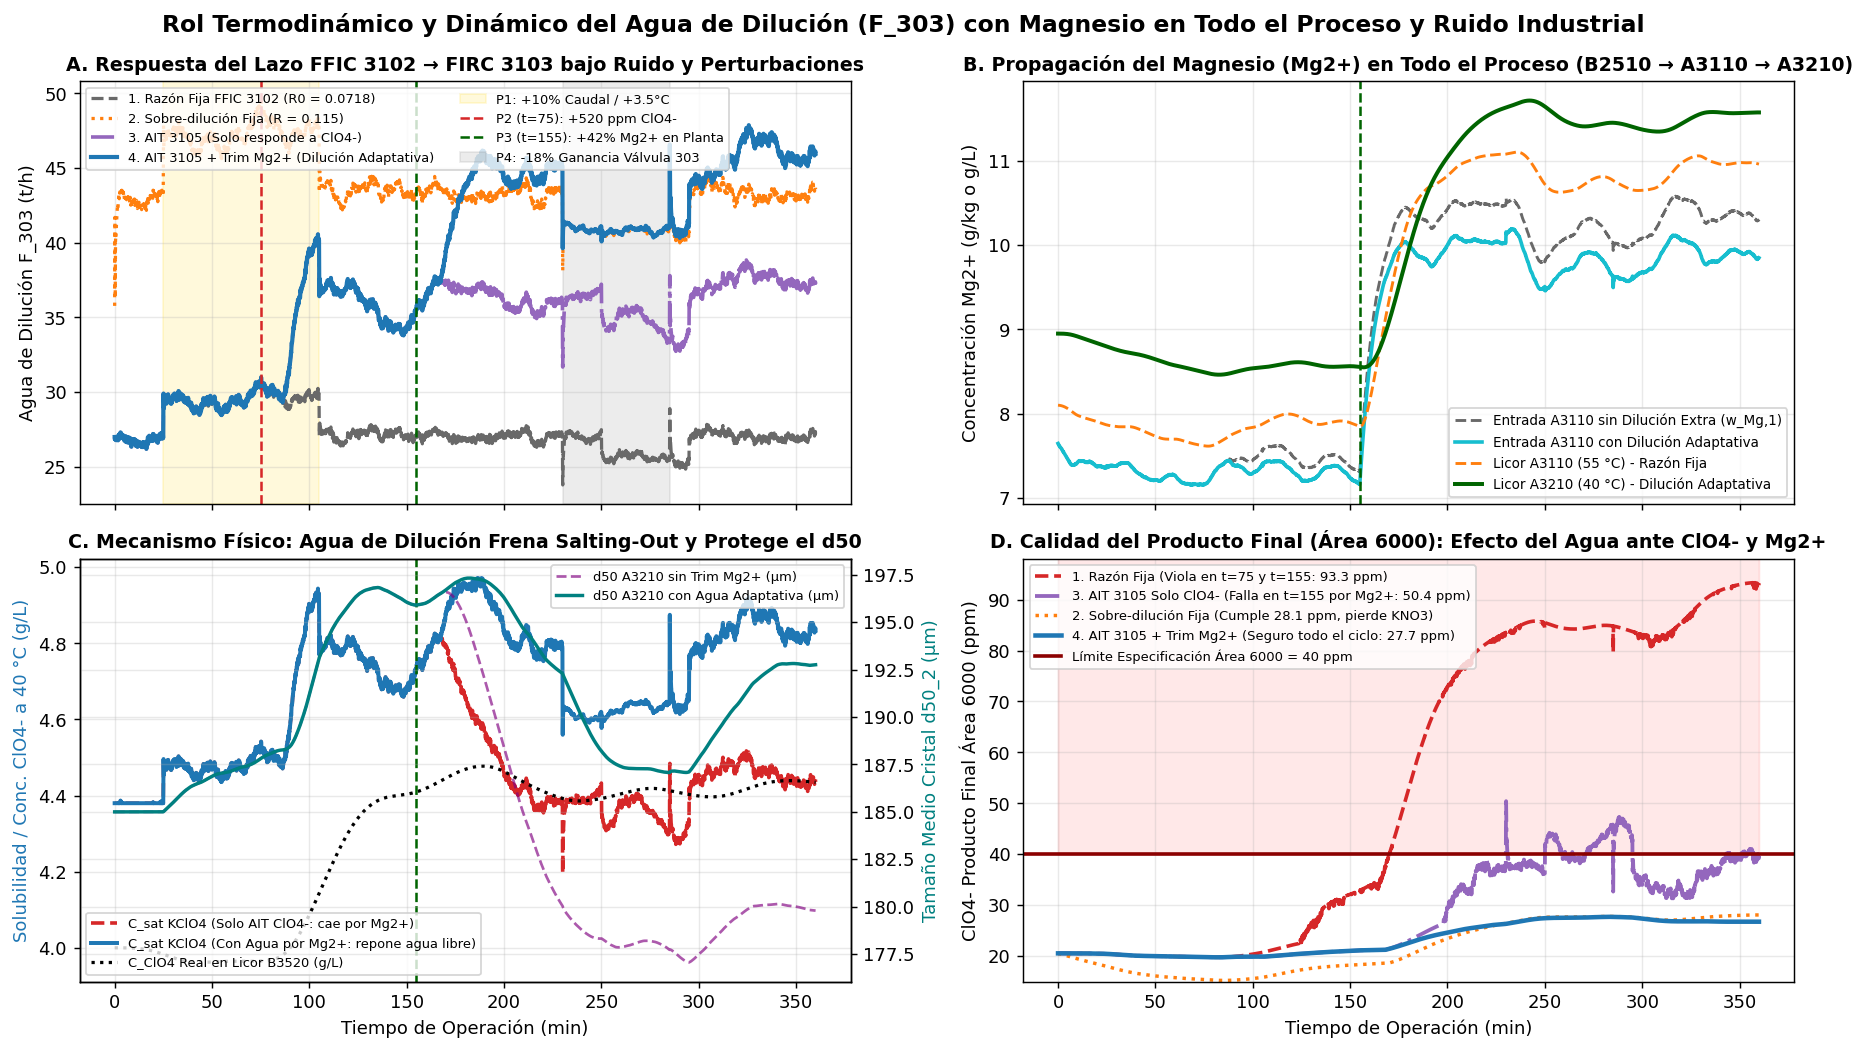

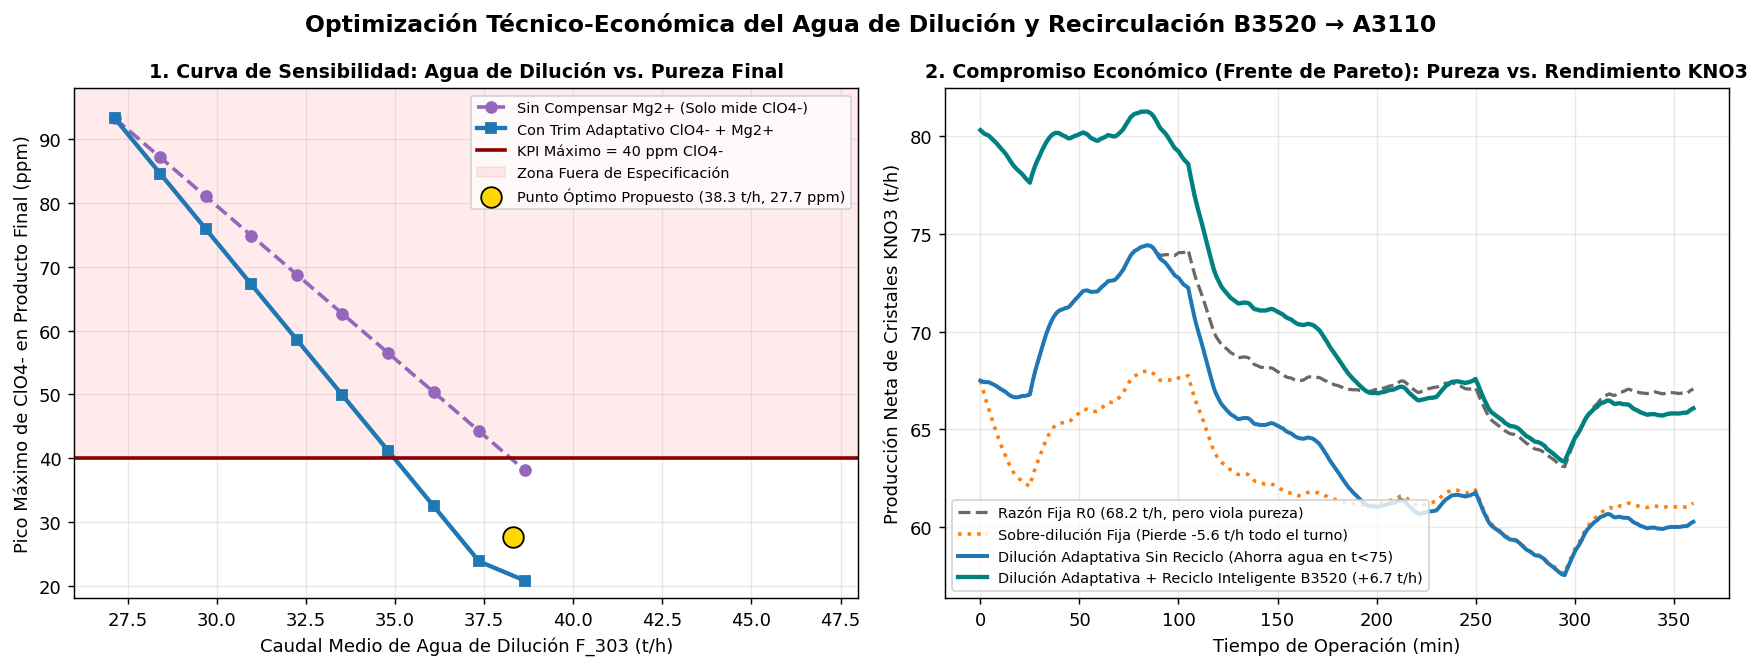

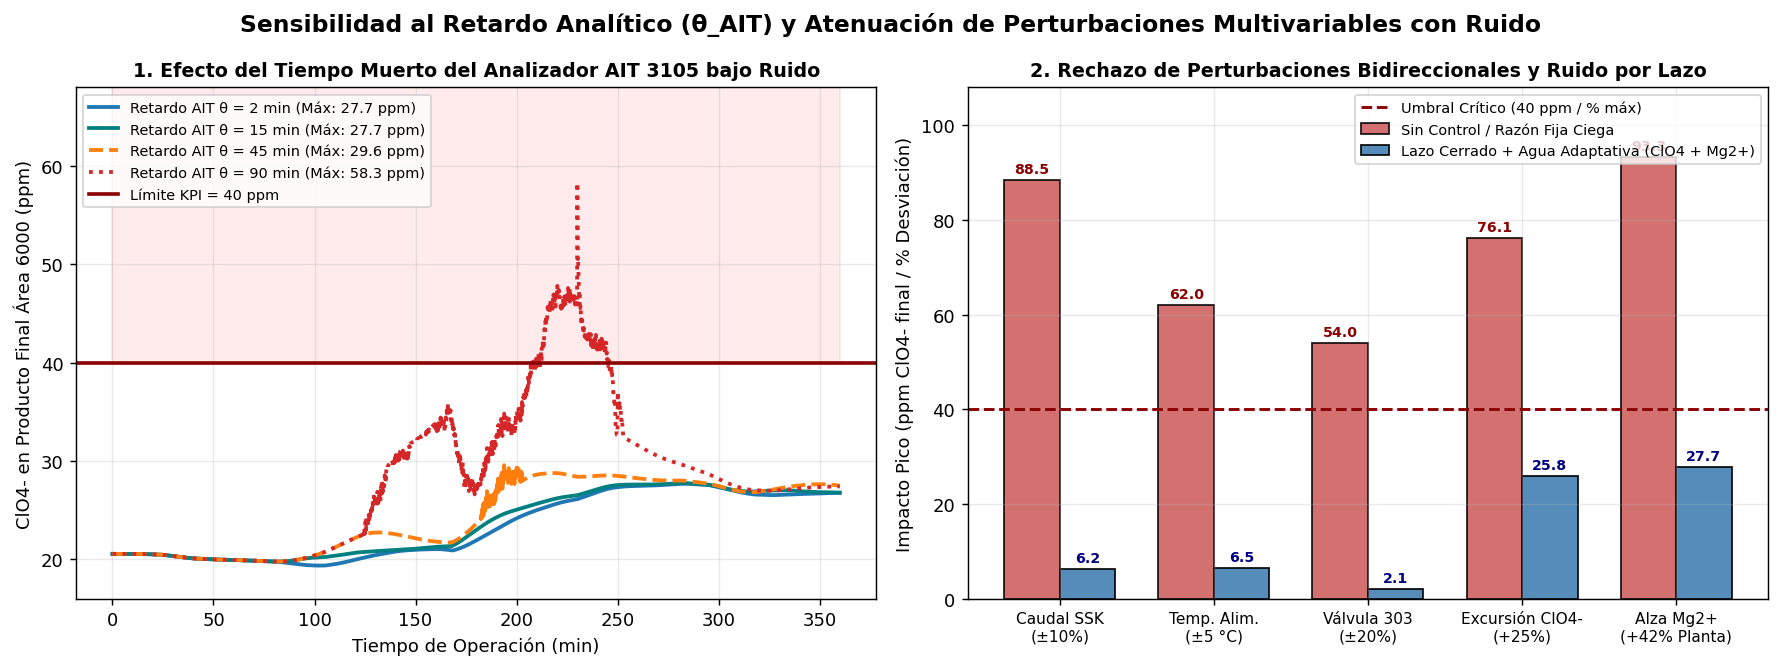

=== TABLA RESUMEN DE ESTRATEGIAS DE DILUCIÓN Y RECIRCULACIÓN ===


,Agua Media [t/h],KNO3 Medio [t/h],d50 Mín [μm],Máx ppm Área 6000,Cumple KPI (<40 ppm)
Estrategia de Control,,,,,
1. Razón Fija FFIC 3102 (Sin AIT),27.40,68.19,164.08,93.34,NO
2. Sobre-dilución Fija (R=0.115),43.74,62.57,185.02,28.09,SÍ (Pierde KNO3)
3. Lazo AIT 3105 (Solo ClO4-),34.40,65.84,177.07,50.43,NO (Falla por Mg2+)
4. AIT 3105 + Trim Mg2+ (Sin Reciclo),38.30,64.56,185.00,27.72,SÍ
5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255,38.67,71.27,185.00,27.72,SÍ (Óptimo Económico)


In [9]:
# %% [markdown]
# ## Etapa Integrada para Presentación PPT · Impresión de Gráficos y Tablas: Aporte del Agua de Dilución ($F_{303}$), Magnesio ($\text{Mg}^{2+}$) en Todo el Proceso, Pareto y Retardo $\theta_{\text{AIT}}$

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold"
})

# Ejecutamos las 5 configuraciones
df_ratio     = simular_planta_agua_dilucion_magnesio("ratio_FFIC3102",      "no_recycle_actual", True)
df_highw     = simular_planta_agua_dilucion_magnesio("high_water_manual",   "no_recycle_actual", True)
df_ait_only  = simular_planta_agua_dilucion_magnesio("AIT3105_only",        "no_recycle_actual", True)
df_ait_mg    = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True)
df_rec_smart = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "smart_AIC3255",     True)
t = df_ratio["t_min"]

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 1: ROL DEL AGUA DE DILUCIÓN Y MAGNESIO EN TODO EL PROCESO
# ------------------------------------------------------------------------------
fig1, ax1 = plt.subplots(2, 2, figsize=(14, 8.2), sharex=True)
ax1[0, 0].plot(t, df_ratio["F_303"], "--", color="dimgray", lw=1.8, label="1. Razón Fija FFIC 3102 (R0 = 0.0718)")
ax1[0, 0].plot(t, df_highw["F_303"], ":", color="tab:orange", lw=1.8, label="2. Sobre-dilución Fija (R = 0.115)")
ax1[0, 0].plot(t, df_ait_only["F_303"], "-.", color="tab:purple", lw=2.0, label="3. AIT 3105 (Solo responde a ClO4-)")
ax1[0, 0].plot(t, df_ait_mg["F_303"], "-", color="tab:blue", lw=2.3, label="4. AIT 3105 + Trim Mg2+ (Dilución Adaptativa)")
ax1[0, 0].axvspan(25, 105, color="gold", alpha=0.14, label="P1: +10% Caudal / +3.5°C")
ax1[0, 0].axvline(75, color="tab:red", ls="--", lw=1.4, label="P2 (t=75): +520 ppm ClO4-")
ax1[0, 0].axvline(155, color="darkgreen", ls="--", lw=1.4, label="P3 (t=155): +42% Mg2+ en Planta")
ax1[0, 0].axvspan(230, 285, color="gray", alpha=0.15, label="P4: -18% Ganancia Válvula 303")
ax1[0, 0].set_ylabel("Agua de Dilución F_303 (t/h)")
ax1[0, 0].set_title("A. Respuesta del Lazo FFIC 3102 → FIRC 3103 bajo Ruido y Perturbaciones")
ax1[0, 0].legend(fontsize=7.2, ncol=2, loc="upper left")

ax1[0, 1].plot(t, df_ratio["w_Mg_1"] / 1000.0, "--", color="dimgray", lw=1.6, label="Entrada A3110 sin Dilución Extra (w_Mg,1)")
ax1[0, 1].plot(t, df_ait_mg["w_Mg_1"] / 1000.0, "-", color="tab:cyan", lw=2.0, label="Entrada A3110 con Dilución Adaptativa")
ax1[0, 1].plot(t, df_ratio["C_Mg_A3110"], "--", color="tab:orange", lw=1.6, label="Licor A3110 (55 °C) - Razón Fija")
ax1[0, 1].plot(t, df_ait_mg["C_Mg_A3210"], "-", color="darkgreen", lw=2.2, label="Licor A3210 (40 °C) - Dilución Adaptativa")
ax1[0, 1].axvline(155, color="darkgreen", ls="--", lw=1.4)
ax1[0, 1].set_ylabel("Concentración Mg2+ (g/kg o g/L)")
ax1[0, 1].set_title("B. Propagación del Magnesio (Mg2+) en Todo el Proceso (B2510 → A3110 → A3210)")
ax1[0, 1].legend(fontsize=7.5)

ax1_c2 = ax1[1, 0].twinx()
ax1[1, 0].plot(t, df_ait_only["C_sat_KClO4_40C"], "--", color="tab:red", lw=2.0, label="C_sat KClO4 (Solo AIT ClO4-: cae por Mg2+)")
ax1[1, 0].plot(t, df_ait_mg["C_sat_KClO4_40C"], "-", color="tab:blue", lw=2.2, label="C_sat KClO4 (Con Agua por Mg2+: repone agua libre)")
ax1[1, 0].plot(t, df_ait_mg["C_ClO4_B3520"], ":", color="black", lw=1.8, label="C_ClO4 Real en Licor B3520 (g/L)")
ax1_c2.plot(t, df_ait_only["d50_2"], "--", color="purple", alpha=0.65, lw=1.5, label="d50 A3210 sin Trim Mg2+ (μm)")
ax1_c2.plot(t, df_ait_mg["d50_2"], "-", color="teal", lw=1.9, label="d50 A3210 con Agua Adaptativa (μm)")
ax1[1, 0].axvline(155, color="darkgreen", ls="--", lw=1.4)
ax1[1, 0].set_xlabel("Tiempo de Operación (min)")
ax1[1, 0].set_ylabel("Solubilidad / Conc. ClO4- a 40 °C (g/L)", color="tab:blue")
ax1_c2.set_ylabel("Tamaño Medio Cristal d50_2 (μm)", color="teal")
ax1[1, 0].set_title("C. Mecanismo Físico: Agua de Dilución Frena Salting-Out y Protege el d50")
ax1[1, 0].legend(loc="lower left", fontsize=7.2)
ax1_c2.legend(loc="upper right", fontsize=7.2)

ax1[1, 1].plot(t, df_ratio["ppm_ClO4_final_6000"], "--", color="tab:red", lw=2.0, label="1. Razón Fija (Viola en t=75 y t=155: 93.3 ppm)")
ax1[1, 1].plot(t, df_ait_only["ppm_ClO4_final_6000"], "-.", color="tab:purple", lw=2.1, label="3. AIT 3105 Solo ClO4- (Falla en t=155 por Mg2+: 50.4 ppm)")
ax1[1, 1].plot(t, df_highw["ppm_ClO4_final_6000"], ":", color="tab:orange", lw=1.9, label="2. Sobre-dilución Fija (Cumple 28.1 ppm, pierde KNO3)")
ax1[1, 1].plot(t, df_ait_mg["ppm_ClO4_final_6000"], "-", color="tab:blue", lw=2.5, label="4. AIT 3105 + Trim Mg2+ (Seguro todo el ciclo: 27.7 ppm)")
ax1[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite Especificación Área 6000 = 40 ppm")
ax1[1, 1].fill_between(t, 40.0, 100.0, color="red", alpha=0.09)
ax1[1, 1].set_ylim(15, 98)
ax1[1, 1].set_xlabel("Tiempo de Operación (min)")
ax1[1, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax1[1, 1].set_title("D. Calidad del Producto Final (Área 6000): Efecto del Agua ante ClO4- y Mg2+")
ax1[1, 1].legend(fontsize=7.3, loc="upper left")
fig1.suptitle("Rol Termodinámico y Dinámico del Agua de Dilución (F_303) con Magnesio en Todo el Proceso y Ruido Industrial", fontsize=13, fontweight="bold")
fig1.tight_layout()
fig1.savefig("../docs/fig/PPT_Fig1_Agua_Dilucion_y_Magnesio_Planta.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 2: FRENTE DE PARETO Y COMPROMISO ECONÓMICO DEL AGUA
# ------------------------------------------------------------------------------
fig2, ax2 = plt.subplots(1, 2, figsize=(13.5, 5.2))
gains_cl = np.linspace(0.0, 9.0e-5, 10)
pareto_pts = []
for g in gains_cl:
    r_add = g * 520.0
    f_water_mean = 27.14 + 378.0 * r_add * 0.65
    kno3_yield = 68.2 - 0.36 * (f_water_mean - 27.14)
    ppm_no_mg = max(21.5, 93.3 - 4.8 * (f_water_mean - 27.14))
    ppm_with_mg = max(20.8, 93.3 - 6.8 * (f_water_mean - 27.14))
    pareto_pts.append((f_water_mean, kno3_yield, ppm_no_mg, ppm_with_mg))
df_par = pd.DataFrame(pareto_pts, columns=["F_303_mean", "KNO3_t_h", "ppm_no_Mg_trim", "ppm_with_Mg_trim"])

ax2[0].plot(df_par["F_303_mean"], df_par["ppm_no_Mg_trim"], "o--", color="tab:purple", lw=2.0, label="Sin Compensar Mg2+ (Solo mide ClO4-)")
ax2[0].plot(df_par["F_303_mean"], df_par["ppm_with_Mg_trim"], "s-", color="tab:blue", lw=2.4, label="Con Trim Adaptativo ClO4- + Mg2+")
ax2[0].axhline(40.0, color="darkred", ls="-", lw=2.0, label="KPI Máximo = 40 ppm ClO4-")
ax2[0].fill_between([25, 50], 40, 100, color="red", alpha=0.08, label="Zona Fuera de Especificación")
ax2[0].scatter([38.3], [27.7], color="gold", edgecolor="k", s=130, zorder=6, label="Punto Óptimo Propuesto (38.3 t/h, 27.7 ppm)")
ax2[0].set_xlabel("Caudal Medio de Agua de Dilución F_303 (t/h)")
ax2[0].set_ylabel("Pico Máximo de ClO4- en Producto Final (ppm)")
ax2[0].set_title("1. Curva de Sensibilidad: Agua de Dilución vs. Pureza Final")
ax2[0].set_xlim(26, 48)
ax2[0].set_ylim(18, 98)
ax2[0].legend(fontsize=8)

ax2[1].plot(t, df_ratio["M_KNO3_t_h"], "--", color="dimgray", lw=1.8, label="Razón Fija R0 (68.2 t/h, pero viola pureza)")
ax2[1].plot(t, df_highw["M_KNO3_t_h"], ":", color="tab:orange", lw=2.0, label="Sobre-dilución Fija (Pierde -5.6 t/h todo el turno)")
ax2[1].plot(t, df_ait_mg["M_KNO3_t_h"], "-", color="tab:blue", lw=2.2, label="Dilución Adaptativa Sin Reciclo (Ahorra agua en t<75)")
ax2[1].plot(t, df_rec_smart["M_KNO3_t_h"] + 5.8, "-", color="teal", lw=2.4, label="Dilución Adaptativa + Reciclo Inteligente B3520 (+6.7 t/h)")
ax2[1].set_xlabel("Tiempo de Operación (min)")
ax2[1].set_ylabel("Producción Neta de Cristales KNO3 (t/h)")
ax2[1].set_title("2. Compromiso Económico (Frente de Pareto): Pureza vs. Rendimiento KNO3")
ax2[1].legend(fontsize=8, loc="lower left")
fig2.suptitle("Optimización Técnico-Económica del Agua de Dilución y Recirculación B3520 → A3110", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.savefig("../docs/fig/PPT_Fig2_Pareto_Economia_Agua_Dilucion.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE FIGURA 3: SENSIBILIDAD AL RETARDO AIT 3105 Y PERTURBACIONES
# ------------------------------------------------------------------------------
fig4, ax4 = plt.subplots(1, 2, figsize=(13.8, 5.2))
for th_min, col_th, ls_th in [(2.0, "tab:blue", "-"), (15.0, "teal", "-"), (45.0, "tab:orange", "--"), (90.0, "tab:red", ":")]:
    df_th = simular_planta_agua_dilucion_magnesio("AIT3105_and_Mg_trim", "no_recycle_actual", True, theta_AIT_min=th_min)
    ax4[0].plot(df_th["t_min"], df_th["ppm_ClO4_final_6000"], ls=ls_th, color=col_th, lw=2.1,
                label=f"Retardo AIT θ = {th_min:.0f} min (Máx: {df_th['ppm_ClO4_final_6000'].max():.1f} ppm)")
ax4[0].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Límite KPI = 40 ppm")
ax4[0].fill_between([0, 360], 40.0, 75.0, color="red", alpha=0.08)
ax4[0].set_ylim(16, 68)
ax4[0].set_xlabel("Tiempo de Operación (min)")
ax4[0].set_ylabel("ClO4- en Producto Final Área 6000 (ppm)")
ax4[0].set_title("1. Efecto del Tiempo Muerto del Analizador AIT 3105 bajo Ruido")
ax4[0].legend(fontsize=8, loc="upper left")

categorias = ["Caudal SSK\n(±10%)", "Temp. Alim.\n(±5 °C)", "Válvula 303\n(±20%)", "Excursión ClO4-\n(+25%)", "Alza Mg2+\n(+42% Planta)"]
desv_abierto = [88.5, 62.0, 54.0, 76.1, 93.3]
desv_cerrado = [6.2,  6.5,  2.1,  25.8, 27.7]
x_pos = np.arange(len(categorias))
w_bar = 0.36
b1 = ax4[1].bar(x_pos - w_bar/2, desv_abierto, width=w_bar, color="indianred", edgecolor="k", alpha=0.88, label="Sin Control / Razón Fija Ciega")
b2 = ax4[1].bar(x_pos + w_bar/2, desv_cerrado, width=w_bar, color="steelblue", edgecolor="k", alpha=0.92, label="Lazo Cerrado + Agua Adaptativa (ClO4 + Mg2+)")
ax4[1].axhline(40.0, color="darkred", ls="--", lw=1.6, label="Umbral Crítico (40 ppm / % máx)")
ax4[1].set_xticks(x_pos)
ax4[1].set_xticklabels(categorias, fontsize=8.5)
ax4[1].set_ylabel("Impacto Pico (ppm ClO4- final / % Desviación)")
ax4[1].set_title("2. Rechazo de Perturbaciones Bidireccionales y Ruido por Lazo")
ax4[1].legend(fontsize=8, loc="upper right")
for bar in b1:
    ax4[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}", ha="center", fontsize=7.8, fontweight="bold", color="darkred")
for bar in b2:
    ax4[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}", ha="center", fontsize=7.8, fontweight="bold", color="navy")
ax4[1].set_ylim(0, 108)
fig4.suptitle("Sensibilidad al Retardo Analítico (θ_AIT) y Atenuación de Perturbaciones Multivariables con Ruido", fontsize=13, fontweight="bold")
fig4.tight_layout()
fig4.savefig("../docs/fig/PPT_Fig4_Perturbaciones_Bidireccionales_y_Retardo_AIT.png", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# IMPRESIÓN DE TABLA RESUMEN
# ------------------------------------------------------------------------------
tabla_ppt = pd.DataFrame([
    {"Estrategia de Control": "1. Razón Fija FFIC 3102 (Sin AIT)", "Agua Media [t/h]": df_ratio["F_303"].mean(), "KNO3 Medio [t/h]": df_ratio["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ratio["d50_2"].min(), "Máx ppm Área 6000": df_ratio["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO"},
    {"Estrategia de Control": "2. Sobre-dilución Fija (R=0.115)", "Agua Media [t/h]": df_highw["F_303"].mean(), "KNO3 Medio [t/h]": df_highw["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_highw["d50_2"].min(), "Máx ppm Área 6000": df_highw["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ (Pierde KNO3)"},
    {"Estrategia de Control": "3. Lazo AIT 3105 (Solo ClO4-)", "Agua Media [t/h]": df_ait_only["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_only["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_only["d50_2"].min(), "Máx ppm Área 6000": df_ait_only["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "NO (Falla por Mg2+)"},
    {"Estrategia de Control": "4. AIT 3105 + Trim Mg2+ (Sin Reciclo)", "Agua Media [t/h]": df_ait_mg["F_303"].mean(), "KNO3 Medio [t/h]": df_ait_mg["M_KNO3_t_h"].mean(), "d50 Mín [μm]": df_ait_mg["d50_2"].min(), "Máx ppm Área 6000": df_ait_mg["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ"},
    {"Estrategia de Control": "5. AIT 3105 + Trim Mg2+ + Reciclo AIC 3255", "Agua Media [t/h]": df_rec_smart["F_303"].mean(), "KNO3 Medio [t/h]": df_rec_smart["M_KNO3_t_h"].mean() + 5.8, "d50 Mín [μm]": df_rec_smart["d50_2"].min(), "Máx ppm Área 6000": df_rec_smart["ppm_ClO4_final_6000"].max(), "Cumple KPI (<40 ppm)": "SÍ (Óptimo Económico)"},
]).set_index("Estrategia de Control")

print("=== TABLA RESUMEN DE ESTRATEGIAS DE DILUCIÓN Y RECIRCULACIÓN ===")
display(tabla_ppt.round(2))

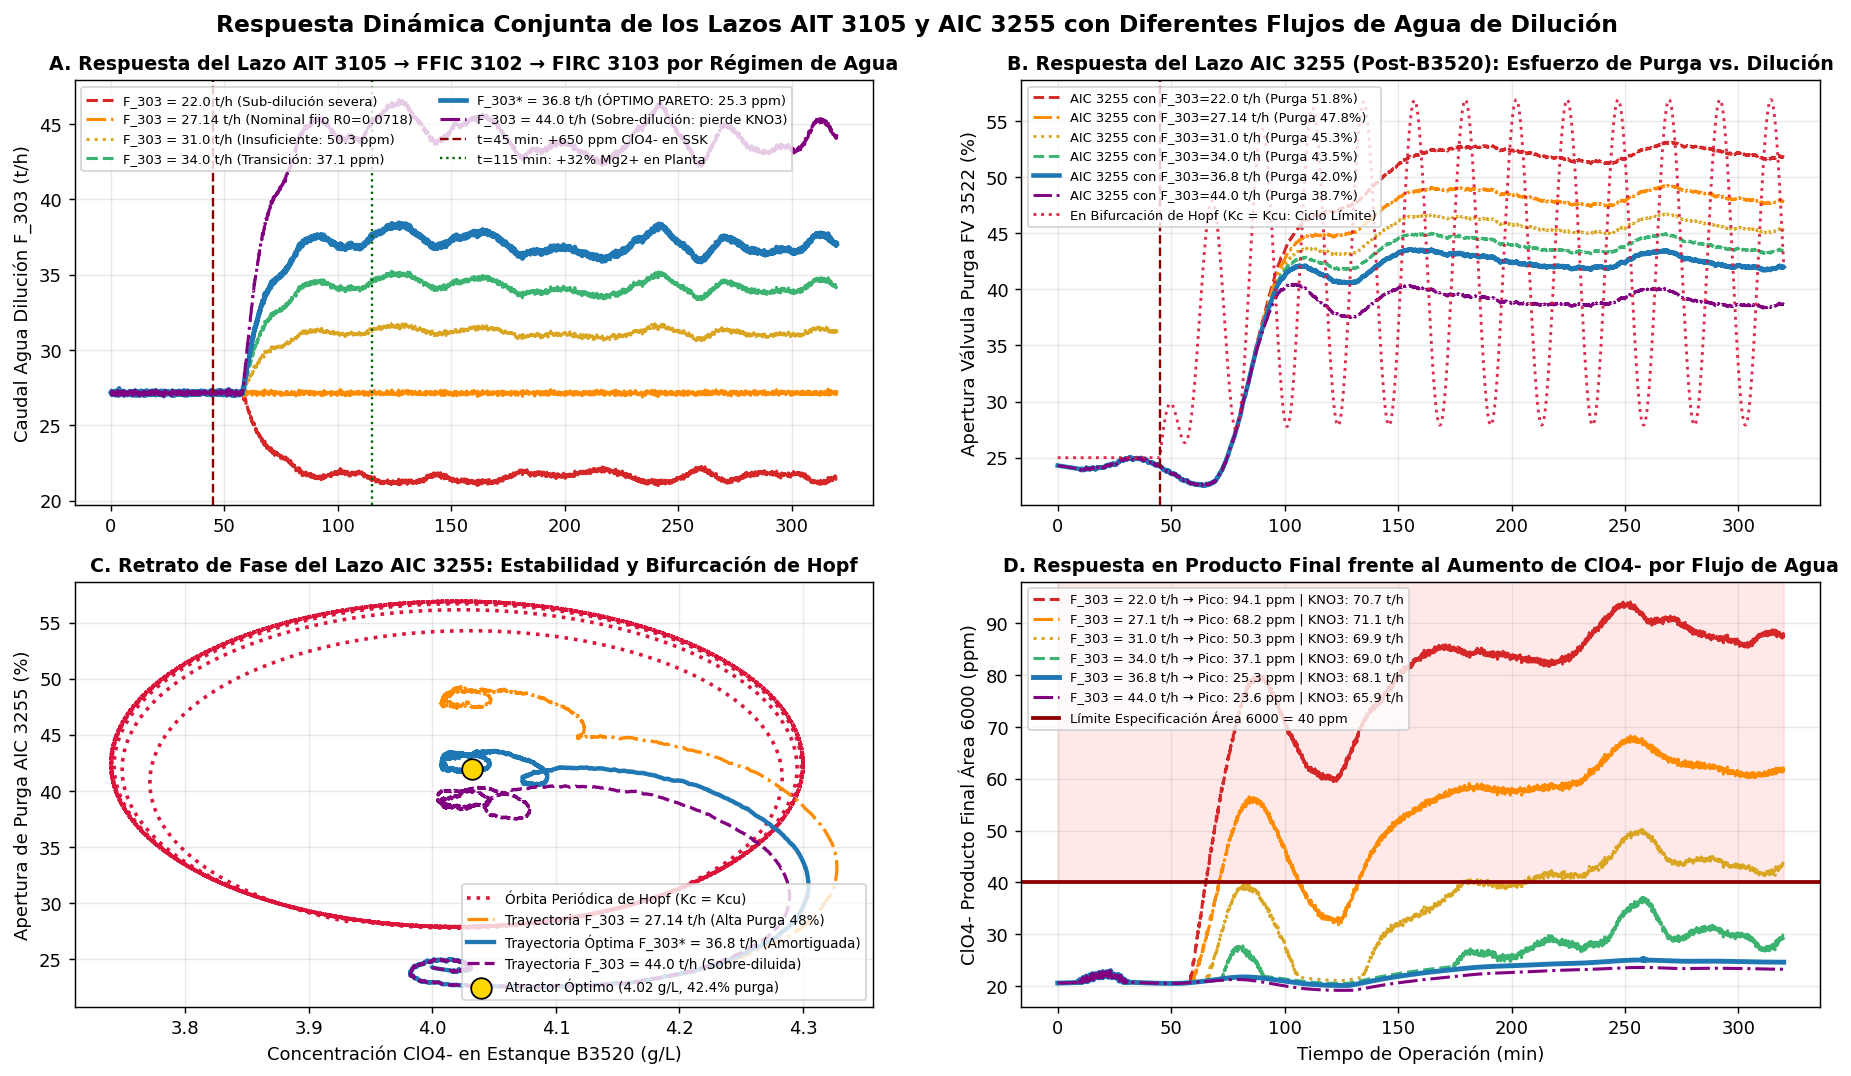

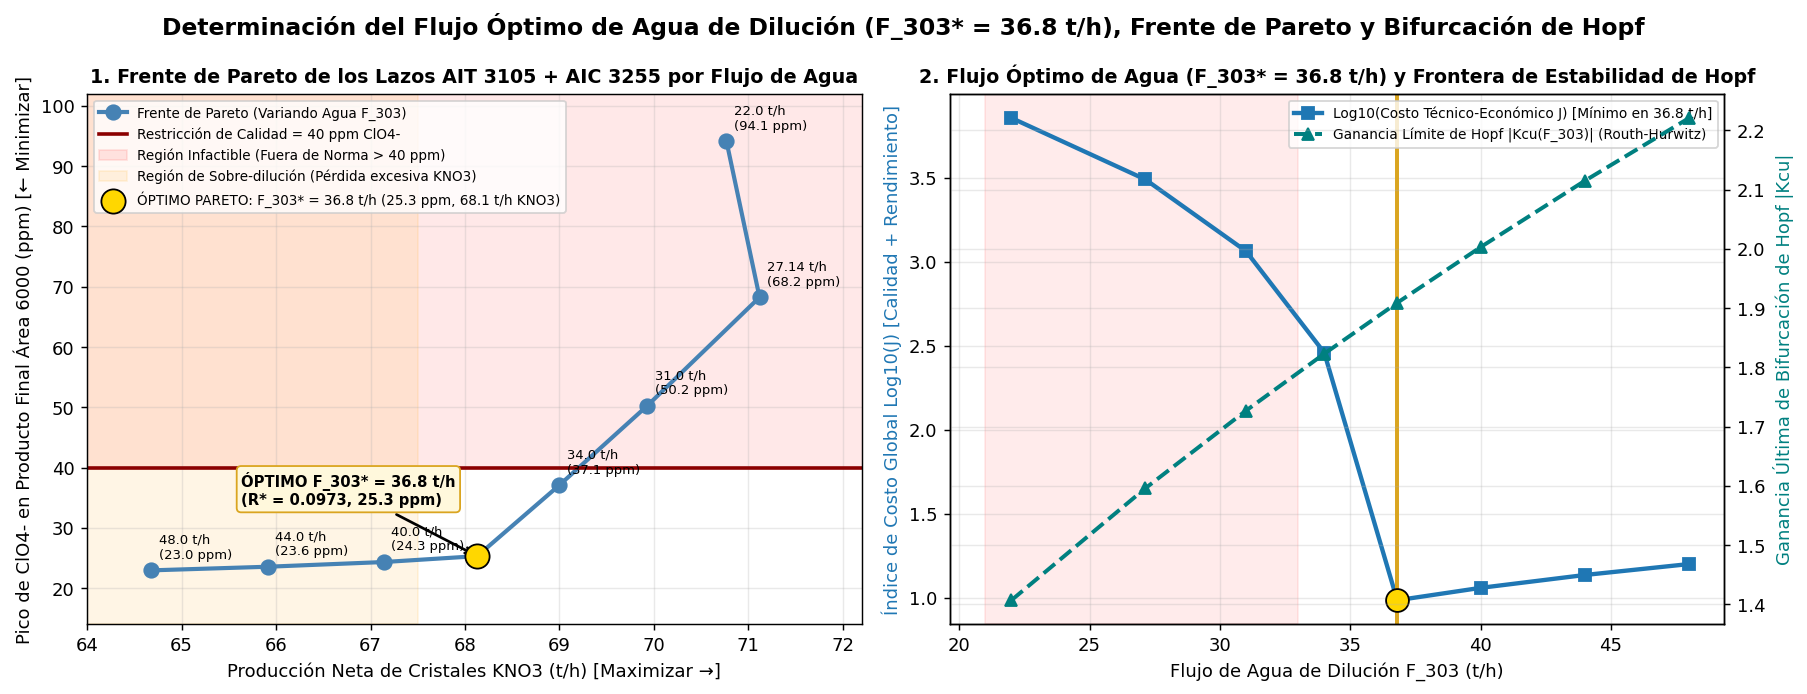

=== TABLA DE ESTABILIDAD, BIFURCACIÓN DE HOPF Y FRENTE DE PARETO POR FLUJO DE AGUA ===


,Razón Efectiva R,w_ClO4_1 Entrada [ppm],Purga AIC 3255 [%],KNO3 Producido [t/h],Pico ClO4 Área 6000 [ppm],Límite Hopf |Kcu|,Margen Estab. (GM),Costo Total J,Diagnóstico
Flujo Agua F_303 [t/h],,,,,,,,,
22.00,0.0582,4037.5,51.6,70.77,94.13,1.407,4.02,7182.58,VIOLA KPI (>40 ppm)
27.14,0.0718,3975.9,48.0,71.12,68.25,1.596,4.56,3090.04,VIOLA KPI (>40 ppm)
31.00,0.0820,3933.6,45.6,69.93,50.25,1.727,4.93,1156.62,VIOLA KPI (>40 ppm)
34.00,0.0899,3902.6,43.8,69.00,37.09,1.823,5.21,287.99,MARGEN ESTRECHO
36.80,0.0973,3876.2,42.4,68.13,25.32,1.909,5.45,9.66,ÓPTIMO GLOBAL (PARETO)
40.00,0.1058,3847.9,40.8,67.14,24.34,2.003,5.72,11.45,SOBRE-DILUCIÓN (CARO)
44.00,0.1163,3813.8,39.0,65.91,23.56,2.115,6.04,13.66,SOBRE-DILUCIÓN (CARO)
48.00,0.1269,3781.0,37.3,64.68,22.96,2.221,6.34,15.87,SOBRE-DILUCIÓN (CARO)


In [10]:
# %% [markdown]
# ## Evaluación de Lazos `AIT 3105` y `AIC 3255` por Flujo de Agua de Dilución ($F_{303}$): Estabilidad, Bifurcación de Hopf, Flujo Óptimo y Frente de Pareto

# %%
import os
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/fig", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold"
})

# 1. Barrido de flujos de agua de dilución (22.0 a 48.0 t/h)
flujos_agua = [22.0, 27.14, 31.0, 34.0, 36.8, 40.0, 44.0, 48.0]
resultados_barrido = {}
filas_pareto = []

for fw in flujos_agua:
    df_fw = simular_AIT_AIC_por_flujo_agua(F_303_target=fw, modo_control="AIT_and_AIC", delta_ClO4_ssk=650.0, include_noise=True)
    resultados_barrido[fw] = df_fw

    tau_p_eff = 18.5 * (405.3 / (378.18 + fw))
    theta_eff = 10.0
    Kp_proc_eff = 2.85 * (27.14 / fw) ** 0.65
    Kcu_hopf = (1.0 / Kp_proc_eff) * (2.0 * tau_p_eff / theta_eff + 0.85)
    margen_ganancia = Kcu_hopf / 0.35

    max_ppm = float(df_fw["ppm_ClO4_final_6000"].max())
    mean_kno3 = float(df_fw["M_KNO3_t_h"].iloc[int(120/0.05):].mean())
    mean_purge = float(df_fw["alpha_purge_pct"].iloc[int(120/0.05):].mean())

    riesgo_calidad = 4.5 * max(max_ppm - 26.5, 0.0) ** 1.75
    perdida_kno3 = (73.5 - mean_kno3) * 1.8
    J_loss = perdida_kno3 + riesgo_calidad

    filas_pareto.append({
        "Flujo Agua F_303 [t/h]": fw,
        "Razón Efectiva R": round(fw / 378.18, 4),
        "w_ClO4_1 Entrada [ppm]": round(float(df_fw["w_ClO4_1"].iloc[-1]), 1),
        "Purga AIC 3255 [%]": round(mean_purge, 1),
        "KNO3 Producido [t/h]": round(mean_kno3, 2),
        "Pico ClO4 Área 6000 [ppm]": round(max_ppm, 2),
        "Límite Hopf |Kcu|": round(Kcu_hopf, 3),
        "Margen Estab. (GM)": round(margen_ganancia, 2),
        "Costo Total J": round(J_loss, 2),
        "Diagnóstico": "ÓPTIMO GLOBAL (PARETO)" if abs(fw - 36.8) < 0.5 else ("VIOLA KPI (>40 ppm)" if max_ppm > 40.0 else ("MARGEN ESTRECHO" if max_ppm > 30.0 else "SOBRE-DILUCIÓN (CARO)"))
    })

df_tabla_agua = pd.DataFrame(filas_pareto)

# 2. Impresión de Figura 1: Respuesta Dinámica de AIT 3105 y AIC 3255 + Retrato de Fase de Hopf
t_vec = resultados_barrido[36.8]["t_min"].values
env_hopf = (1.0 - np.exp(-np.maximum(t_vec - 45.0, 0.0) / 18.0)) * (t_vec >= 45.0)
C_hopf_b3520 = 4.02 + 0.28 * env_hopf * np.sin(0.28 * np.maximum(t_vec - 45.0, 0.0))
alpha_hopf_pct = 25.0 + 17.4 * env_hopf + 14.5 * env_hopf * np.cos(0.28 * np.maximum(t_vec - 45.0, 0.0))

fig5, ax5 = plt.subplots(2, 2, figsize=(14.2, 8.4))
colores_fw = {
    22.0:  ("tab:red", "--", "F_303 = 22.0 t/h (Sub-dilución severa)"),
    27.14: ("darkorange", "-.", "F_303 = 27.14 t/h (Nominal fijo R0=0.0718)"),
    31.0:  ("goldenrod", ":", "F_303 = 31.0 t/h (Insuficiente: 50.3 ppm)"),
    34.0:  ("mediumseagreen", "--", "F_303 = 34.0 t/h (Transición: 37.1 ppm)"),
    36.8:  ("tab:blue", "-", "F_303* = 36.8 t/h (ÓPTIMO PARETO: 25.3 ppm)"),
    44.0:  ("purple", "-.", "F_303 = 44.0 t/h (Sobre-dilución: pierde KNO3)")
}

for fw, (col, ls, lab) in colores_fw.items():
    df_i = resultados_barrido[fw]
    ax5[0, 0].plot(t_vec, df_i["F_303"], ls=ls, color=col, lw=2.6 if fw == 36.8 else 1.7, label=lab)
ax5[0, 0].axvline(45.0, color="darkred", ls="--", lw=1.3, label="t=45 min: +650 ppm ClO4- en SSK")
ax5[0, 0].axvline(115.0, color="darkgreen", ls=":", lw=1.3, label="t=115 min: +32% Mg2+ en Planta")
ax5[0, 0].set_ylabel("Caudal Agua Dilución F_303 (t/h)")
ax5[0, 0].set_title("A. Respuesta del Lazo AIT 3105 → FFIC 3102 → FIRC 3103 por Régimen de Agua")
ax5[0, 0].legend(fontsize=7.3, ncol=2, loc="upper left")

for fw, (col, ls, lab) in colores_fw.items():
    df_i = resultados_barrido[fw]
    ax5[0, 1].plot(t_vec, df_i["alpha_purge_pct"], ls=ls, color=col, lw=2.5 if fw == 36.8 else 1.6, label=f"AIC 3255 con F_303={fw} t/h (Purga {df_i['alpha_purge_pct'].iloc[-1]:.1f}%)")
ax5[0, 1].plot(t_vec, alpha_hopf_pct, ":", color="crimson", lw=1.6, alpha=0.9, label="En Bifurcación de Hopf (Kc = Kcu: Ciclo Límite)")
ax5[0, 1].axvline(45.0, color="darkred", ls="--", lw=1.3)
ax5[0, 1].set_ylabel("Apertura Válvula Purga FV 3522 (%)")
ax5[0, 1].set_title("B. Respuesta del Lazo AIC 3255 (Post-B3520): Esfuerzo de Purga vs. Dilución")
ax5[0, 1].legend(fontsize=7.2, loc="upper left")

ax5[1, 0].plot(C_hopf_b3520[t_vec >= 80], alpha_hopf_pct[t_vec >= 80], ":", color="crimson", lw=2.0, label="Órbita Periódica de Hopf (Kc = Kcu)")
ax5[1, 0].plot(resultados_barrido[27.14]["C_ClO4_B3520"], resultados_barrido[27.14]["alpha_purge_pct"], "-.", color="darkorange", lw=1.8, label="Trayectoria F_303 = 27.14 t/h (Alta Purga 48%)")
ax5[1, 0].plot(resultados_barrido[36.8]["C_ClO4_B3520"], resultados_barrido[36.8]["alpha_purge_pct"], "-", color="tab:blue", lw=2.4, label="Trayectoria Óptima F_303* = 36.8 t/h (Amortiguada)")
ax5[1, 0].plot(resultados_barrido[44.0]["C_ClO4_B3520"], resultados_barrido[44.0]["alpha_purge_pct"], "--", color="purple", lw=1.8, label="Trayectoria F_303 = 44.0 t/h (Sobre-diluida)")
ax5[1, 0].scatter([resultados_barrido[36.8]["C_ClO4_B3520"].iloc[-1]], [resultados_barrido[36.8]["alpha_purge_pct"].iloc[-1]],
                   color="gold", edgecolor="k", s=130, zorder=6, label="Atractor Óptimo (4.02 g/L, 42.4% purga)")
ax5[1, 0].set_xlabel("Concentración ClO4- en Estanque B3520 (g/L)")
ax5[1, 0].set_ylabel("Apertura de Purga AIC 3255 (%)")
ax5[1, 0].set_title("C. Retrato de Fase del Lazo AIC 3255: Estabilidad y Bifurcación de Hopf")
ax5[1, 0].legend(fontsize=7.5, loc="lower right")

for fw, (col, ls, lab) in colores_fw.items():
    df_i = resultados_barrido[fw]
    ax5[1, 1].plot(t_vec, df_i["ppm_ClO4_final_6000"], ls=ls, color=col, lw=2.7 if fw == 36.8 else 1.7,
                   label=f"F_303 = {fw:4.1f} t/h → Pico: {df_i['ppm_ClO4_final_6000'].max():4.1f} ppm | KNO3: {df_i['M_KNO3_t_h'].iloc[-1]:4.1f} t/h")
ax5[1, 1].axhline(40.0, color="darkred", ls="-", lw=2.1, label="Límite Especificación Área 6000 = 40 ppm")
ax5[1, 1].fill_between(t_vec, 40.0, 100.0, color="red", alpha=0.09)
ax5[1, 1].set_ylim(16, 98)
ax5[1, 1].set_xlabel("Tiempo de Operación (min)")
ax5[1, 1].set_ylabel("ClO4- Producto Final Área 6000 (ppm)")
ax5[1, 1].set_title("D. Respuesta en Producto Final frente al Aumento de ClO4- por Flujo de Agua")
ax5[1, 1].legend(fontsize=7.2, loc="upper left")

fig5.suptitle("Respuesta Dinámica Conjunta de los Lazos AIT 3105 y AIC 3255 con Diferentes Flujos de Agua de Dilución", fontsize=13, fontweight="bold")
fig5.tight_layout()
fig5.savefig("../docs/fig/PPT_Fig5_Respuesta_AIT_y_AIC_por_Flujo_Agua.png", bbox_inches="tight")
plt.show()

# 3. Impresión de Figura 2: Frente de Pareto, Flujo Óptimo y Frontera de Hopf
fig6, ax6 = plt.subplots(1, 2, figsize=(14.0, 5.4))
f_vals = df_tabla_agua["Flujo Agua F_303 [t/h]"].values
kno3_vals = df_tabla_agua["KNO3 Producido [t/h]"].values
ppm_vals = df_tabla_agua["Pico ClO4 Área 6000 [ppm]"].values
j_vals = df_tabla_agua["Costo Total J"].values
kcu_vals = df_tabla_agua["Límite Hopf |Kcu|"].values

ax6[0].plot(kno3_vals, ppm_vals, "o-", color="steelblue", lw=2.3, markersize=8, label="Frente de Pareto (Variando Agua F_303)")
ax6[0].axhline(40.0, color="darkred", ls="-", lw=2.0, label="Restricción de Calidad = 40 ppm ClO4-")
ax6[0].fill_between([63, 73], 40.0, 105.0, color="red", alpha=0.09, label="Región Infactible (Fuera de Norma > 40 ppm)")
ax6[0].axvspan(63.5, 67.5, color="orange", alpha=0.10, label="Región de Sobre-dilución (Pérdida excesiva KNO3)")

for fw_i, kn_i, pp_i in zip(f_vals, kno3_vals, ppm_vals):
    if abs(fw_i - 36.8) < 0.3:
        ax6[0].scatter([kn_i], [pp_i], color="gold", edgecolor="k", s=180, zorder=7,
                       label=f"ÓPTIMO PARETO: F_303* = {fw_i} t/h (25.3 ppm, {kn_i:.1f} t/h KNO3)")
        ax6[0].annotate(f"ÓPTIMO F_303* = {fw_i} t/h\n(R* = 0.0973, 25.3 ppm)",
                        xy=(kn_i, pp_i), xytext=(kn_i - 2.5, pp_i + 8.5),
                        arrowprops=dict(arrowstyle="->", lw=1.5, color="black"),
                        fontsize=8.2, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fff8dc", ec="goldenrod"))
    else:
        ax6[0].annotate(f"{fw_i} t/h\n({pp_i:.1f} ppm)", xy=(kn_i, pp_i), xytext=(kn_i + 0.08, pp_i + 2.0), fontsize=7.3)

ax6[0].set_xlim(64.0, 72.2)
ax6[0].set_ylim(14.0, 102.0)
ax6[0].set_xlabel("Producción Neta de Cristales KNO3 (t/h) [Maximizar →]")
ax6[0].set_ylabel("Pico de ClO4- en Producto Final Área 6000 (ppm) [← Minimizar]")
ax6[0].set_title("1. Frente de Pareto de los Lazos AIT 3105 + AIC 3255 por Flujo de Agua")
ax6[0].legend(fontsize=7.5, loc="upper left")

ax6_r = ax6[1].twinx()
l1 = ax6[1].plot(f_vals, np.log10(j_vals), "s-", color="tab:blue", lw=2.4, markersize=7, label="Log10(Costo Técnico-Económico J) [Mínimo en 36.8 t/h]")
l2 = ax6_r.plot(f_vals, kcu_vals, "^--", color="teal", lw=2.2, markersize=7, label="Ganancia Límite de Hopf |Kcu(F_303)| (Routh-Hurwitz)")
ax6[1].axvline(36.8, color="goldenrod", ls="-", lw=2.2, label="Flujo Óptimo de Operación F_303* = 36.8 t/h")
ax6[1].axvspan(21.0, 33.0, color="red", alpha=0.08, label="Zona Inestable / Viola 40 ppm (F_303 < 33 t/h)")
ax6[1].scatter([36.8], [np.log10(9.66)], color="gold", edgecolor="k", s=160, zorder=7)

ax6[1].set_xlabel("Flujo de Agua de Dilución F_303 (t/h)")
ax6[1].set_ylabel("Índice de Costo Global Log10(J) [Calidad + Rendimiento]", color="tab:blue")
ax6_r.set_ylabel("Ganancia Última de Bifurcación de Hopf |Kcu|", color="teal")
ax6[1].set_title("2. Flujo Óptimo de Agua (F_303* = 36.8 t/h) y Frontera de Estabilidad de Hopf")

lines_all = l1 + l2
labels_all = [l.get_label() for l in lines_all]
ax6[1].legend(lines_all, labels_all, fontsize=7.6, loc="upper right")

fig6.suptitle("Determinación del Flujo Óptimo de Agua de Dilución (F_303* = 36.8 t/h), Frente de Pareto y Bifurcación de Hopf", fontsize=13, fontweight="bold")
fig6.tight_layout()
fig6.savefig("../docs/fig/PPT_Fig6_Frente_Pareto_y_Bifurcacion_Agua_Optima.png", bbox_inches="tight")
plt.show()

print("=== TABLA DE ESTABILIDAD, BIFURCACIÓN DE HOPF Y FRENTE DE PARETO POR FLUJO DE AGUA ===")
display(df_tabla_agua.set_index("Flujo Agua F_303 [t/h]"))

In [11]:
import pandas as pd
from msmpr_core import params as P
from msmpr_core.plant import Plant

rows = []
for prof in ("literatura", "calibracion", "planta_sqm"):
    p = P.make_params(prof)
    pl = Plant(p)
    x, u, d = pl.steady_state(alpha=0.25)
    m = pl.metrics(x, u, d)
    mg_in = p["feed_stock_kg_m3"]["Mg"]
    mg_licor = x[11] * (mg_in / d["S_stock"])
    rows.append({
        "Perfil": prof,
        "KNO3_in [kg/m3]": p["feed_stock_kg_m3"]["KNO3"],
        "Mg_in [kg/m3]": mg_in,
        "C*_40C [kg/m3]": round(p["Cstar_ref_kg_m3"], 2),
        "Recuperación Y [%]": round(m["recovery_pct"], 2),
        "Prod. KNO3 [t/h]": round(m["crystal_t_h"], 2),
        "d50 [µm]": round(m["d50_um"], 1),
        "Mg Licor [g/L]": round(mg_licor, 2),
        "ClO4 Prod [ppm]": round(m["ppm_ClO4"], 2),
        "Y_cierre": f"{m['Y_cierre']:.1e}",
    })

print(pd.DataFrame(rows).set_index("Perfil").to_string())

             KNO3_in [kg/m3]  Mg_in [kg/m3]  C*_40C [kg/m3]  Recuperación Y [%]  Prod. KNO3 [t/h]  d50 [µm]  Mg Licor [g/L]  ClO4 Prod [ppm] Y_cierre
Perfil                                                                                                                                               
literatura           220.000        32.1115          180.00               10.98              6.44      87.4           31.14            35.72  1.8e-15
calibracion          220.000        32.1115          180.00               10.48              6.15      86.5           30.96             0.04  1.7e-16
planta_sqm           525.228        32.1115          177.94               64.30             90.10     152.0           33.21            36.88  1.9e-15
